# Desarrollo 02: lago urbano en China, la primera mejora del algoritmo

El notebook 01 dejo el metodo mas simple que funciono en el ejemplo mas facil, el rio Meguro. Aqui se sigue la regla de esta carpeta: **se copia ese notebook cambiando solo la configuracion, se mira que falla, y se cambia solo lo que el fallo obliga**.

**Resultado.** En las 5 secciones (234 fotos, 173 con lectura manual), **la v2 da un error absoluto medio de 0.68 cm y 94.6 % en +-2 cm**; la copia sin cambios lee sobre la mira seca: 31.22 cm y 0.6 % en +-2 cm con ese mismo cero. En la **serie completa, la v2 da 0.57 cm, 97.65 % en +-2 cm y 99.33 % en +-5 cm** (2682 fotos). Se estima con la referencia una constante de cero. **En Meguro, con el valor neutro `FOTO_SECA = None`, no cambia ninguna de las 53 lecturas; con los parametros activos empeora** (1.49 cm y 84 % en +-2 cm, frente a 1.11 cm y 92 %), asi que alli la memoria debe ir apagada. No es una prueba del todo a ciegas: seccion 4.2.

| Parte | |
|---|---|
| 1. Copia del notebook 01 | mismo codigo, solo cambia la configuracion. Tabla de valores Meguro / China |
| 2. Problemas | que salio mal, con figuras y su causa, y que no dio problema |
| 3. Cambios al codigo | cada cambio con su fallo y su diff literal; lista de lineas comprobada contra el notebook 01 |
| 4. Resultados en China | por seccion, v1 y v2 (tabla principal), serie completa aparte, video |
| 5. Comprobacion en Meguro | el mismo codigo v2 en las 53 fotos del ejemplo 1, foto por foto |
| 6. Limitaciones | que queda sin resolver |

**De donde sale cada numero.** Las partes 1 a 3 y la tabla principal se calculan solo sobre **5 secciones** de la serie (234 fotos). La **serie completa** (3315 fotos) es una validacion final de la v2 y se da aparte, en la seccion 4.3.

# 1. Copia del notebook 01

## 1.1 Preparacion y datos

**Datos.** [Zenodo 10812125](https://zenodo.org/records/10812125), CC BY 4.0: 3315 fotos de 3840 x 2160 px de una camara fija sobre la mira de un lago urbano del sur de China, una cada 15 min, del 27-may al 6-jul-2023; de noche la camara pasa a infrarrojo. La lectura manual de 2691 fotos es la referencia, y **solo se abre en la seccion 4.2**.

**Las secciones.** Son bloques continuos de la serie, sin quitar ninguna foto de dentro. **Se eligieron solo mirando las imagenes**, en hojas con varias fotos de cada dia, y con una regla fijada antes de medir:

| Seccion | Bloque | Como se eligio |
|---|---|---|
| dia, agua quieta | 27-may 06:00 a 17:30 | agua quieta y reflejo claro: el primer dia de la serie |
| dia, agua rizada | 11-jun 09:30 a 16:00 | el primer bloque de dia de unas 6 h en que no se ve reflejo |
| noche | 27-may 20:00 a 28-may 05:00 | infrarrojo: la primera noche completa |
| cambio brusco | 4-jul 11:00 a 20:00 | el agua sube ~17 cm en menos de dos horas, con lluvia; es la mayor crecida visible |
| vaciado | 19-jun, todo el dia | el agua mas baja de la serie; incluye la foto seca de la seccion 3 |

**Cautela sobre la eleccion.** La referencia no se habia abierto al fijarlas. Si se conocia, de pruebas sin referencia, que el metodo falla en parte de las fotos de finales de mayo; por eso se uso la regla "el primero" y no un dia elegido a mano, y ese dia queda dentro.

Con `SOLO_SECCIONES = True` el notebook corre en pocos minutos y lee la serie completa de un CSV guardado; con `False` la vuelve a medir.

In [1]:
import ast
import difflib
import json
import os
import sys
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

sys.path.insert(0, os.path.join("..", "herramientas"))
import escritor_video                     # escribe H.264 por una tuberia a ffmpeg (cv2.VideoWriter no sirve aqui)

plt.rcParams.update({"figure.dpi": 90, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8984", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.labelcolor": "#52514e"})

# Colores de las figuras: rojo = linea de agua, azul = ventanas, amarillo = marcas y lectura a ojo
ROJO, AZUL, NARANJA, AMARILLO = "#e34948", "#2a78d6", "#eb6834", "#eda100"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"

SOLO_SECCIONES = True     # True: solo las secciones, la serie completa se lee del CSV guardado. False: se vuelve a medir la serie completa

DATOS = os.path.join("..", "01_zenodo_lago_china", "datos", "SAM_water_level_Dataset")
CARPETA_FOTOS = os.path.join(DATOS, "Staff gauge images")
EXCEL_REFERENCIA = os.path.join(DATOS, "In-situ water levels", "In-situ & simulated water levels.xlsx")   # solo se abre en la seccion 4.2
SALIDAS = "salidas"
os.makedirs(SALIDAS, exist_ok=True)

TEXTO_NIVEL = (0, 0, 0, 0)                # x0, y0, x1, y1: en este ejemplo no hay nivel impreso que tapar


def leer(archivo):
    img = cv2.imread(os.path.join(CARPETA_FOTOS, archivo))
    x0, y0, x1, y1 = TEXTO_NIVEL
    img[y0:y1, x0:x1] = 0
    return img


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def gris(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)


def hora_de(archivo):
    # P23052700112410.jpg -> 2023-05-27 00:11:24 (hora local que imprime la camara)
    return datetime.strptime(os.path.basename(archivo)[1:13], "%y%m%d%H%M%S")


fotos = sorted(os.path.relpath(os.path.join(r, f), CARPETA_FOTOS).replace("\\", "/")
               for r, _, fs in os.walk(CARPETA_FOTOS) for f in fs if f.endswith(".jpg"))
print("%d fotos, de %s a %s" % (len(fotos), hora_de(fotos[0]), hora_de(fotos[-1])))

# >>> AJUSTABLE <<< las secciones: bloques continuos, elegidos solo con la imagen
SECCIONES = {"dia, agua quieta": ("2023-05-27 06:00", "2023-05-27 17:30"),
             "dia, agua rizada": ("2023-06-11 09:30", "2023-06-11 16:00"),
             "noche": ("2023-05-27 20:00", "2023-05-28 05:00"),
             "cambio brusco": ("2023-07-04 11:00", "2023-07-04 20:00"),
             "vaciado": ("2023-06-19 00:00", "2023-06-19 23:59")}


def seccion_de(archivo):
    h = hora_de(archivo)
    for nombre, (t0, t1) in SECCIONES.items():
        if pd.Timestamp(t0) <= h <= pd.Timestamp(t1):
            return nombre
    return None


fotos_s = [a for a in fotos if seccion_de(a) is not None]
print("En las secciones: %d fotos" % len(fotos_s), {s: sum(seccion_de(a) == s for a in fotos_s) for s in SECCIONES})

3315 fotos, de 2023-05-27 00:11:24 a 2023-07-06 10:56:17
En las secciones: 234 fotos {'dia, agua quieta': 46, 'dia, agua rizada': 26, 'noche': 36, 'cambio brusco': 36, 'vaciado': 90}


## 1.2 Una foto

La mira tiene un numero cada 10 cm y una marca en E cada 2 cm. Debajo de la linea de agua se ve su reflejo.

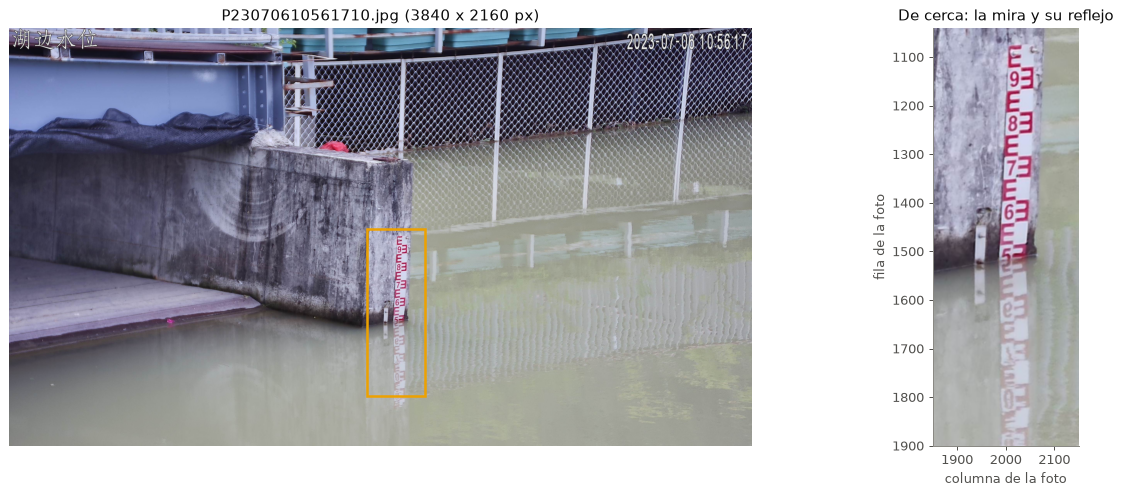

In [2]:
FOTO = "20230706/images/P23070610561710.jpg"     # la foto con la que se explica el metodo
img = leer(FOTO)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [2.6, 1]})
ax[0].imshow(rgb(img)); ax[0].axis("off")
ax[0].set_title("%s (%d x %d px)" % (os.path.basename(FOTO), img.shape[1], img.shape[0]), color=TINTA)
ax[0].add_patch(Rectangle((1850, 1040), 300, 860, fill=False, ec=AMARILLO, lw=2))
ax[1].imshow(rgb(img[1040:1900, 1850:2150]), extent=[1850, 2150, 1900, 1040], interpolation="bicubic")
ax[1].set_title("De cerca: la mira y su reflejo", color=TINTA)
ax[1].set_xlabel("columna de la foto"); ax[1].set_ylabel("fila de la foto")
plt.tight_layout()